# W7-D2 · Introduction to Convolutional Neural Networks (CNNs)
## UCAB · Faculty of Engineering
## School of Software Engineering
## **INFO-02020: Artificial Intelligence: Machine Learning**
### **Instructor:** Prof. Didi Ramsaran Chin  

---

### 🗺️ Table of Contents
- [Module 1: Input Representation & Preprocessing](#module-1-input-representation--preprocessing)
- [Module 2: Feature Extraction Mechanics (Convolutions & Kernels)](#module-2-feature-extraction-mechanics)
- [Module 3: Non-Linearity & Downsampling (Pooling)](#module-3-non-linearity--downsampling-pooling)
- [Module 4: Architectural Hierarchy & Stacking](#module-4-architectural-hierarchy--stacking)
- [Module 5: Feature Transition & Dense Classification](#module-5-feature-transition--dense-classification)
- [Module 6: Output Heads (Single-Head vs. Multi-Head)](#module-6-output-heads)
- [Module 7: Loss Functions & Optimization Strategies](#module-7-loss-functions--optimization-strategies)
- [Full Example: Fashion-MNIST Multi-Head CNN](#full-example-fashion-mnist-multi-head-cnn)


---
## 0. Setup

In [12]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
from scipy.signal import correlate2d
from PIL import Image

# aesthetics
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print(f'Using device: {DEVICE}')


Using device: mps


---
# Module 1: Input Representation & Preprocessing


### Tensors as Image Containers

| Representation | Shape | Example |
|---|---|---|
| Grayscale | $H \times W \times 1$ | MNIST digit |
| Color (RGB) | $H \times W \times 3$ | Natural photo |
| Mini-batch | $B \times C \times H \times W$ | PyTorch convention |


Grayscale shape: (28, 28)
RGB shape: (32, 32, 3)
Batch shape: torch.Size([16, 3, 32, 32])


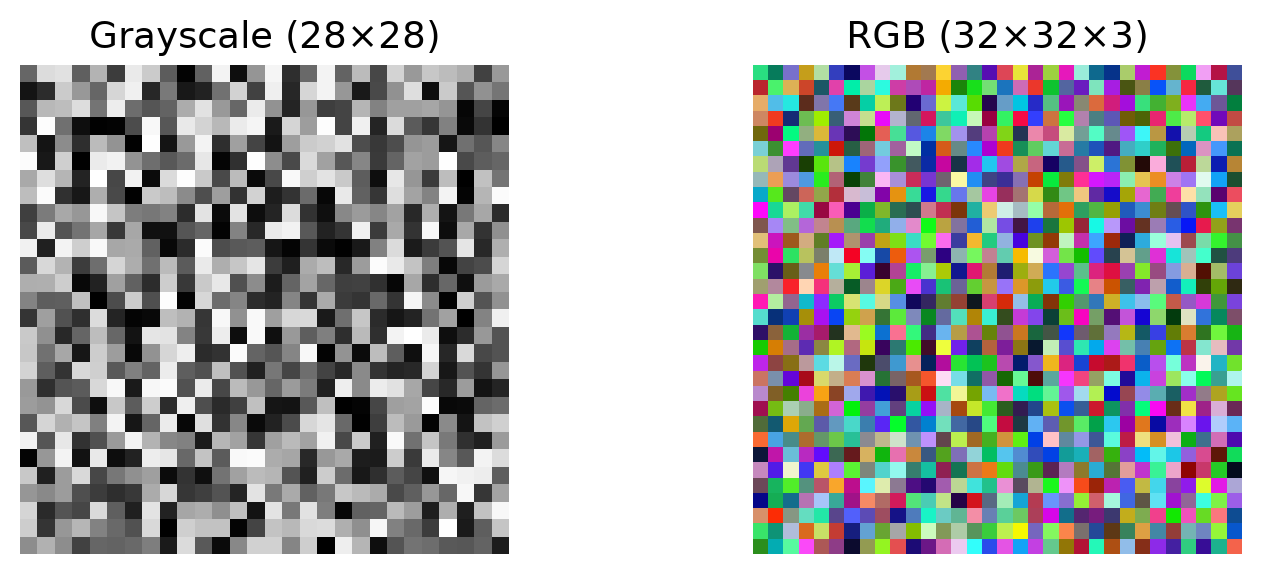

In [14]:
# grayscale image as 2D matrix
gray_img = np.random.randint(0, 256, size=(28, 28), dtype=np.uint8)
print(f'Grayscale shape: {gray_img.shape}')

# RGB image as 3D tensor
rgb_img = np.random.randint(0, 256, size=(32, 32, 3), dtype=np.uint8)
print(f'RGB shape: {rgb_img.shape}')

# mini-batch (PyTorch format: B x C x H x W)
batch = torch.randn(16, 3, 32, 32)
print(f'Batch shape: {batch.shape}')

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(gray_img, cmap='gray'); axes[0].set_title('Grayscale (28×28)')
axes[1].imshow(rgb_img); axes[1].set_title('RGB (32×32×3)')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()


### Preprocessing Pipeline

**Intensity Normalization:** $[0, 255] \rightarrow [0, 1]$ or zero-mean, unit-variance to stabilize gradients.

**Dimension Resizing:** Standardize spatial resolution across heterogeneous inputs.

**Data Augmentation:** Rotations, flips, cropping to prevent overfitting and enforce spatial invariance.


In [15]:
# typical preprocessing pipeline with torchvision transforms
train_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),                    # [0,255] -> [0,1]
    transforms.Normalize((0.5,), (0.5,)),     # zero-mean, unit range
])

test_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

print('Train pipeline:', train_transform)


Train pipeline: Compose(
    Resize(size=(32, 32), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=(0.5,), std=(0.5,))
)


---
# Module 2: Feature Extraction Mechanics


### Kernels vs. Filters

- **Kernel:** Single 2D spatial matrix of learnable weights (e.g., $3 \times 3$).
- **Filter:** Collection of kernels stacked across all input channels (e.g., $3 \times 3 \times 3$ for RGB).

### The 2D Discrete Convolution Operation

$$(I * K)(i, j) = \sum_{m} \sum_{n} \sum_{c} I(i+m, j+n, c) \cdot K(m, n, c)$$

The filter slides across the image, computing element-wise products and summing at each position.


### Interactive Visualization: Convolution Step-by-Step

The visualization below loads the interactive convolution animation from Neuromatch Academy. 
Hover over red-underlined values to change them.


In [16]:
# interactive convolution visualization (Neuromatch Academy)
import os, html, urllib.request
from IPython.display import HTML, display

file_path = os.path.join("static", "interactive_demo2.html")
if os.path.exists(file_path):
    with open(file_path, "r", encoding="utf-8") as f: raw_html = f.read()
else:
    url = "https://raw.githubusercontent.com/NeuromatchAcademy/course-content-dl/main/tutorials/W2D2_Convnets/static/interactive_demo2.html"
    raw_html = urllib.request.urlopen(url).read().decode("utf-8")

srcdoc = html.escape(raw_html, quote=True)
display(HTML(f'<iframe srcdoc="{srcdoc}" width="100%" height="480" frameborder="0"></iframe>'))


/Users/didi/miniforge3/envs/AIAA_INFO_02020/lib/python3.13/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


### Manual Convolution Example

$$\textbf{Image} = \begin{bmatrix}0 & 200 & 200 \\0 & 0 & 200 \\ 0 & 0 & 0 \end{bmatrix}, \quad
\textbf{Kernel} = \begin{bmatrix} 1/4 & 1/4 \\ 1/4 & 1/4 \end{bmatrix}$$

This kernel computes the local **average** (mean pooling / smoothing).


Convolution result (2x2 output):
[[ 50. 150.]
 [  0.  50.]]


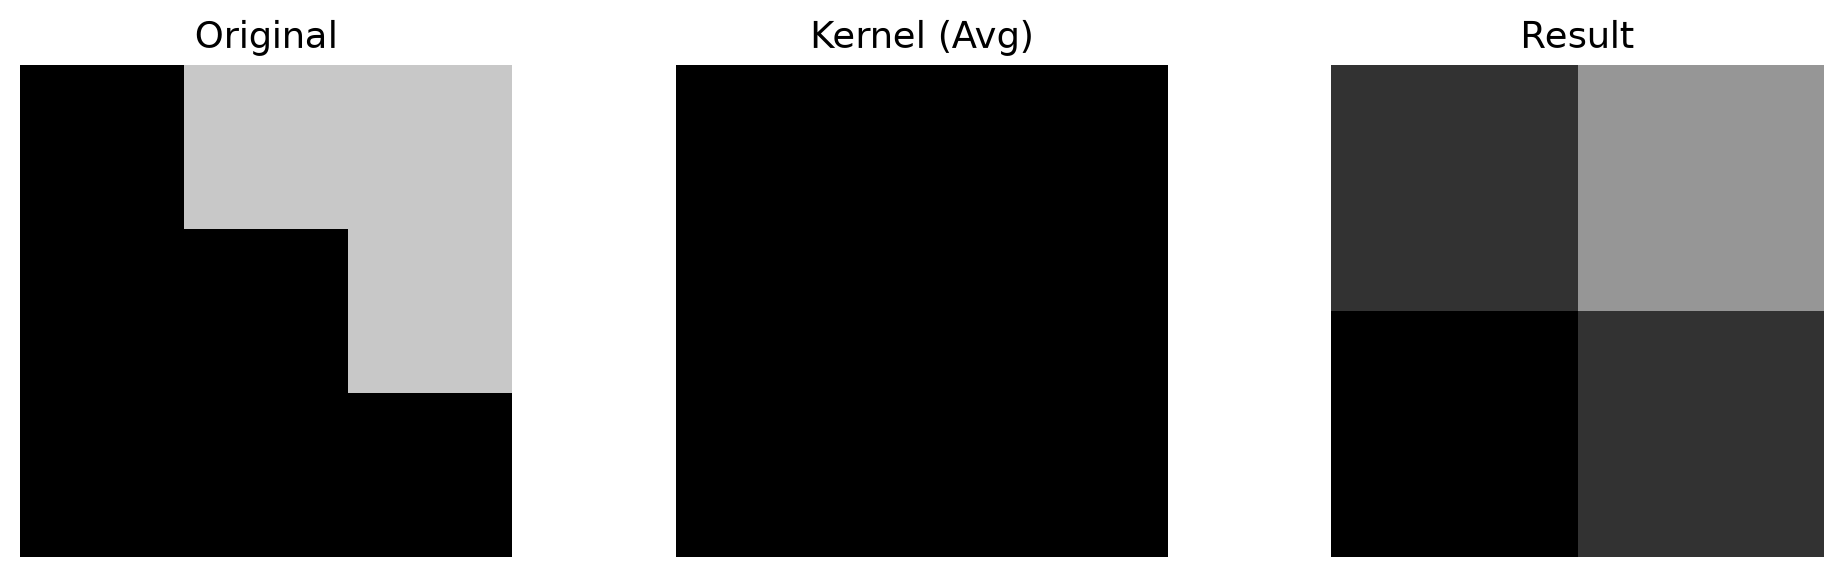

In [17]:
# manual convolution
image = np.array([[0, 200, 200],
                  [0,   0, 200],
                  [0,   0,   0]])

kernel = np.array([[0.25, 0.25],
                   [0.25, 0.25]])

result = correlate2d(image, kernel, mode='valid')
print('Convolution result (2x2 output):')
print(result)

# visualize
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(image, cmap='gray', vmin=0, vmax=255); axes[0].set_title('Original')
axes[1].imshow(kernel, cmap='gray'); axes[1].set_title('Kernel (Avg)')
axes[2].imshow(result, cmap='gray', vmin=0, vmax=255); axes[2].set_title('Result')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()


### Coding a Convolution from Scratch


In [18]:
def my_conv2d(image, kernel):
    """2D convolution (cross-correlation) without padding."""
    ih, iw = image.shape
    kh, kw = kernel.shape
    oh, ow = ih - kh + 1, iw - kw + 1
    output = np.zeros((oh, ow))
    for i in range(oh):
        for j in range(ow):
            output[i, j] = np.sum(image[i:i+kh, j:j+kw] * kernel)
    return output

# verify against scipy
my_result = my_conv2d(image, kernel)
scipy_result = correlate2d(image, kernel, 'valid')
assert np.allclose(my_result, scipy_result), 'Mismatch!'
print('✅ Manual convolution matches scipy')
print(my_result)


✅ Manual convolution matches scipy
[[ 50. 150.]
 [  0.  50.]]


### Spatial Hyperparameters

| Parameter | Description | Effect |
|---|---|---|
| **Stride** $S$ | Step size of filter movement | Larger $S$ → smaller output |
| **Padding** $P$ | Boundary zeros added | Preserves spatial dims |
| **Dilation** $D$ | Spacing between kernel elements | Expands receptive field without more params |

Output size formula: $O = \lfloor\frac{I + 2P - D(K-1) - 1}{S}\rfloor + 1$


### Interactive: Convolution with Padding and Stride


In [19]:
# interactive visualization with padding and stride controls
import os, html, urllib.request
from IPython.display import HTML, display

file_path = os.path.join("static", "interactive_demo2.2.html")
if os.path.exists(file_path):
    with open(file_path, "r", encoding="utf-8") as f: raw_html = f.read()
else:
    url = "https://raw.githubusercontent.com/NeuromatchAcademy/course-content-dl/main/tutorials/W2D2_Convnets/static/interactive_demo2.2.html"
    raw_html = urllib.request.urlopen(url).read().decode("utf-8")

srcdoc = html.escape(raw_html, quote=True)
display(HTML(f'<iframe srcdoc="{srcdoc}" width="100%" height="480" frameborder="0"></iframe>'))


### Edge Detection with Convolution

Edge-detecting kernels are among the first features learned by a CNN.


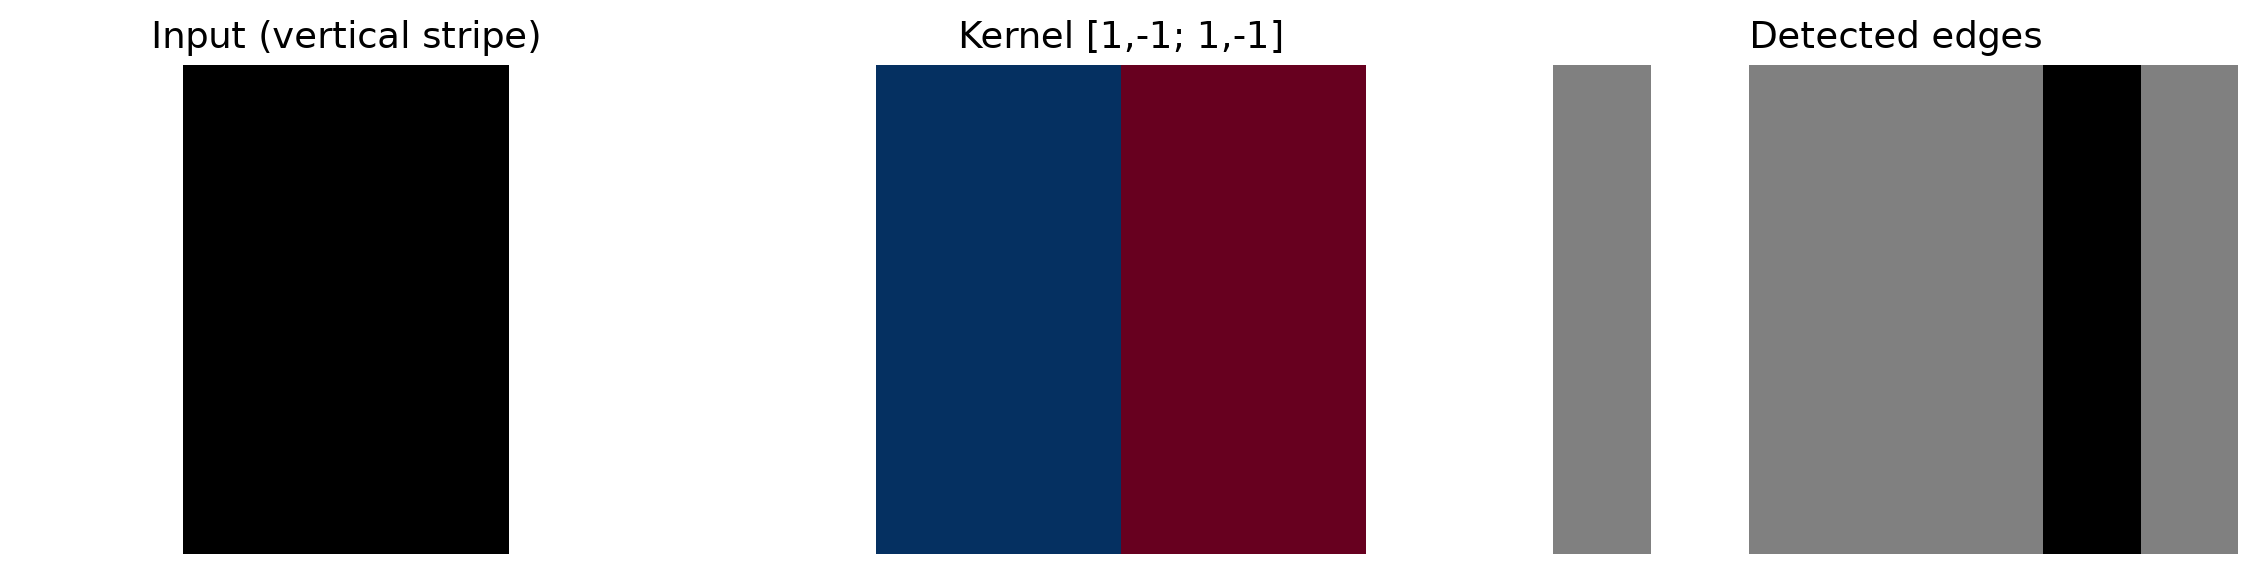

In [20]:
# edge detection demo
# create a vertical stripe image
X = np.ones((6, 8))
X[:, 2:6] = 0

# vertical edge kernel
edge_kernel = np.array([[1.0, -1.0],
                        [1.0, -1.0]])

edges = correlate2d(X, edge_kernel, mode='valid')

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].imshow(X, cmap='gray'); axes[0].set_title('Input (vertical stripe)')
axes[1].imshow(edge_kernel, cmap='RdBu', vmin=-1, vmax=1); axes[1].set_title('Kernel [1,-1; 1,-1]')
axes[2].imshow(edges, cmap='gray'); axes[2].set_title('Detected edges')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()


### PyTorch `nn.Conv2d` in Practice


In [21]:
# PyTorch Conv2d wrapper
class ConvNet(nn.Module):
    def __init__(self, kernel, padding=0):
        super().__init__()
        self.conv = nn.Conv2d(1, 1, kernel_size=kernel.shape, padding=padding, bias=False)
        self.conv.weight = nn.Parameter(kernel.reshape(1, 1, *kernel.shape))

    def forward(self, x):
        return self.conv(x)

# test with edge kernel
k = torch.tensor([[1.0, -1.0], [1.0, -1.0]])
net = ConvNet(k, padding=0)
x_tensor = torch.from_numpy(X).float().reshape(1, 1, 6, 8)
out = net(x_tensor).detach().squeeze().numpy()

print(f'Input shape:  {x_tensor.shape}')
print(f'Output shape: {net(x_tensor).shape}')
print(f'Output:\n{out}')


Input shape:  torch.Size([1, 1, 6, 8])
Output shape: torch.Size([1, 1, 5, 7])
Output:
[[ 0.  2.  0.  0.  0. -2.  0.]
 [ 0.  2.  0.  0.  0. -2.  0.]
 [ 0.  2.  0.  0.  0. -2.  0.]
 [ 0.  2.  0.  0.  0. -2.  0.]
 [ 0.  2.  0.  0.  0. -2.  0.]]


---
# Module 3: Non-Linearity & Downsampling (Pooling)


### Non-Linear Activation Functions

Activations (typically **ReLU**) are applied after convolution to break linear superposition and enable learning of complex boundaries.

$$\text{ReLU}(x) = \max(0, x)$$


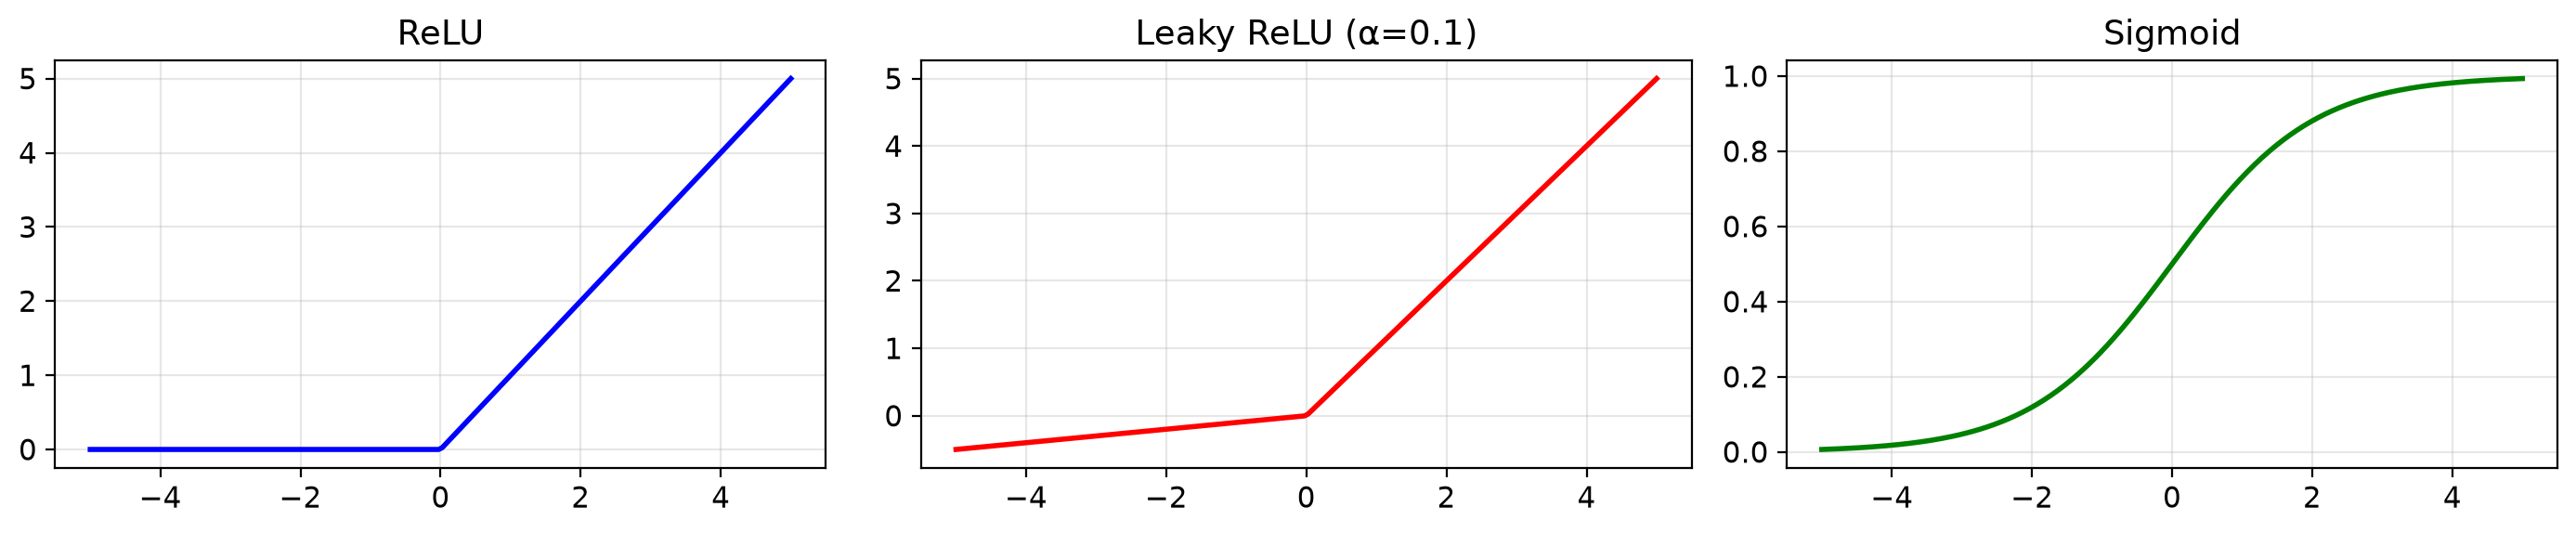

In [22]:
# ReLU visualization
x = torch.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 3, figsize=(14, 3))

# ReLU
axes[0].plot(x, F.relu(x), 'b', lw=2)
axes[0].set_title('ReLU'); axes[0].grid(True, alpha=0.3)

# Leaky ReLU
axes[1].plot(x, F.leaky_relu(x, 0.1), 'r', lw=2)
axes[1].set_title('Leaky ReLU (α=0.1)'); axes[1].grid(True, alpha=0.3)

# Sigmoid
axes[2].plot(x, torch.sigmoid(x), 'g', lw=2)
axes[2].set_title('Sigmoid'); axes[2].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()


### Pooling Layers (Spatial Downsampling)

| Type | Operation | Effect |
|---|---|---|
| **Max Pooling** | Maximum in each window | Emphasizes dominant features, local translation invariance |
| **Average Pooling** | Mean in each window | Smoother feature representations |

Typical: pool size $2 \times 2$, stride $S=2$ → halves spatial dimensions.


### Interactive: Pooling Visualization


In [23]:
# interactive pooling visualization (Neuromatch Academy)
import os, html, urllib.request
from IPython.display import HTML, display

file_path = os.path.join("static", "interactive_demo3.html")
if os.path.exists(file_path):
    with open(file_path, "r", encoding="utf-8") as f: raw_html = f.read()
else:
    url = "https://raw.githubusercontent.com/NeuromatchAcademy/course-content-dl/main/tutorials/W2D2_Convnets/static/interactive_demo3.html"
    raw_html = urllib.request.urlopen(url).read().decode("utf-8")

srcdoc = html.escape(raw_html, quote=True)
display(HTML(f'<iframe srcdoc="{srcdoc}" width="100%" height="480" frameborder="0"></iframe>'))


Input (4x4):
tensor([[1., 3., 2., 4.],
        [5., 6., 1., 2.],
        [3., 2., 7., 8.],
        [0., 1., 3., 5.]])

Max Pool (2x2):
tensor([[6., 4.],
        [3., 8.]])

Avg Pool (2x2):
tensor([[3.7500, 2.2500],
        [1.5000, 5.7500]])


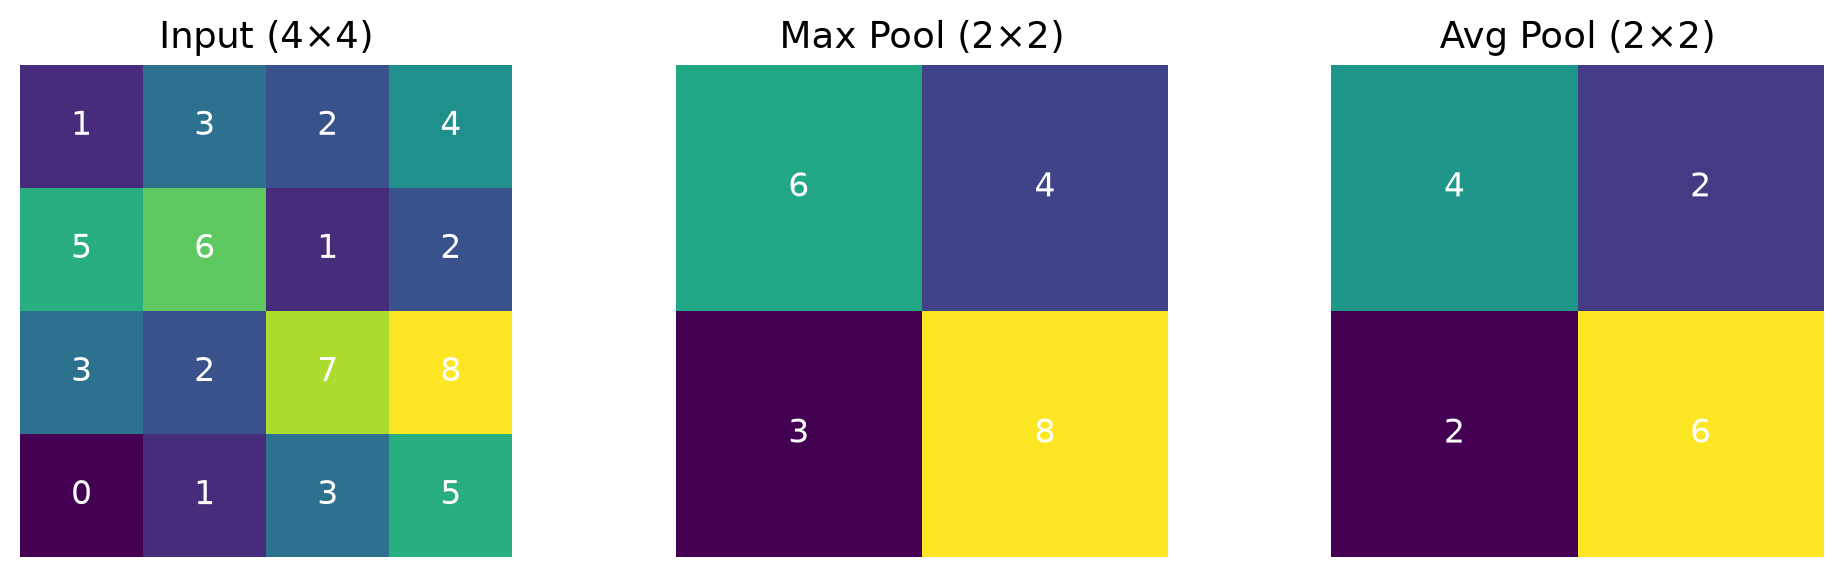

In [24]:
# pooling comparison on a feature map
feature_map = torch.tensor([[[
    [1.0, 3.0, 2.0, 4.0],
    [5.0, 6.0, 1.0, 2.0],
    [3.0, 2.0, 7.0, 8.0],
    [0.0, 1.0, 3.0, 5.0]
]]])

max_pool = F.max_pool2d(feature_map, kernel_size=2, stride=2)
avg_pool = F.avg_pool2d(feature_map, kernel_size=2, stride=2)

print(f'Input (4x4):\n{feature_map.squeeze()}')
print(f'\nMax Pool (2x2):\n{max_pool.squeeze()}')
print(f'\nAvg Pool (2x2):\n{avg_pool.squeeze()}')

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, data, title in zip(axes,
    [feature_map.squeeze(), max_pool.squeeze(), avg_pool.squeeze()],
    ['Input (4×4)', 'Max Pool (2×2)', 'Avg Pool (2×2)']):
    im = ax.imshow(data, cmap='viridis')
    ax.set_title(title)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f'{data[i,j]:.0f}', ha='center', va='center', color='white', fontsize=12)
    ax.axis('off')
plt.tight_layout(); plt.show()


---
# Module 4: Architectural Hierarchy & Stacking


### Layer Repetition & Feature Abstraction

Stacking blocks of `[Conv → Activation → Pooling]` repeatedly:

| Depth | Features Detected |
|---|---|
| **Early layers** | Edges, corners, color gradients |
| **Mid layers** | Textures, simple shapes, object parts |
| **Deep layers** | Entire objects, semantic categories |

**Receptive Field Expansion:** Each deeper layer observes larger regions of the original input.

### Batch Normalization

Normalizes activations across the batch dimension after convolutions to mitigate internal covariate shift:

$$\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}$$


In [25]:
# building a conv block with BatchNorm
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, padding=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size, padding=padding),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )
    def forward(self, x):
        return self.block(x)

# demo: stack 3 blocks, observe spatial reduction
x = torch.randn(1, 1, 32, 32)
for i, ch in enumerate([16, 32, 64]):
    in_ch = 1 if i == 0 else [16, 32][i-1]
    block = ConvBlock(in_ch, ch)
    x = block(x)
    print(f'After block {i+1} ({in_ch}→{ch}): {x.shape}')


After block 1 (1→16): torch.Size([1, 16, 16, 16])
After block 2 (16→32): torch.Size([1, 32, 8, 8])
After block 3 (32→64): torch.Size([1, 64, 4, 4])


---
# Module 5: Feature Transition & Dense Classification


### Transition to Vector Space

| Method | Description | Pros |
|---|---|---|
| **Flatten** | Unroll $C \times H \times W$ → $C \cdot H \cdot W$ | Retains all spatial info |
| **Global Average Pooling (GAP)** | Average each feature map to a scalar → $C$ | Fewer params, resists overfitting |

### Fully Connected (Dense) Layers

Integrate spatial features into non-linear combinations for classification. **Dropout** is applied to prevent co-adaptation.


In [26]:
# flatten vs global average pooling comparison
x = torch.randn(1, 64, 4, 4)  # after conv blocks

# flatten
flat = x.view(x.size(0), -1)
print(f'Flatten: {x.shape} → {flat.shape}  ({flat.shape[1]} features)')

# global average pooling
gap = F.adaptive_avg_pool2d(x, 1).view(x.size(0), -1)
print(f'GAP:     {x.shape} → {gap.shape}  ({gap.shape[1]} features)')


Flatten: torch.Size([1, 64, 4, 4]) → torch.Size([1, 1024])  (1024 features)
GAP:     torch.Size([1, 64, 4, 4]) → torch.Size([1, 64])  (64 features)


---
# Module 6: Output Heads


### Single-Head Output

| Task | Output Dim | Activation |
|---|---|---|
| Binary Classification | 1 | Sigmoid |
| Multi-Class ($N$ classes) | $N$ | Softmax |

### Multi-Head Output (Multi-Task Learning)

Shared convolutional backbone feeding separate task-specific branches:

- **Classification + Bounding Box Regression** (YOLO, R-CNN)
- **Attribute Multi-Tasking** (age + gender + emotion from face)


In [27]:
# single-head vs multi-head architecture sketch
class SingleHeadCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, 32), ConvBlock(32, 64)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

class MultiHeadCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.backbone = nn.Sequential(
            ConvBlock(1, 32), ConvBlock(32, 64)
        )
        # head 1: classification
        self.cls_head = nn.Sequential(
            nn.Flatten(), nn.Linear(64*8*8, 128), nn.ReLU(), nn.Linear(128, num_classes)
        )
        # head 2: regression (e.g., predict image brightness)
        self.reg_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 1)
        )
    def forward(self, x):
        features = self.backbone(x)
        cls_out = self.cls_head(features)
        reg_out = self.reg_head(features)
        return cls_out, reg_out

# verify shapes
x = torch.randn(4, 1, 32, 32)
sh = SingleHeadCNN(10)
mh = MultiHeadCNN(10)
print(f'Single-head output: {sh(x).shape}')
cls, reg = mh(x)
print(f'Multi-head cls: {cls.shape}, reg: {reg.shape}')


Single-head output: torch.Size([4, 10])
Multi-head cls: torch.Size([4, 10]), reg: torch.Size([4, 1])


---
# Module 7: Loss Functions & Optimization Strategies


### Loss Functions per Task

**Classification:**
$$\mathcal{L}_{\text{cls}} = -\sum_{i} y_i \log(\hat{y}_i)$$

**Regression:**
$$\mathcal{L}_{\text{reg}} = \text{Smooth}_{L1}(y - \hat{y})$$

### Combined Loss for Multi-Head

$$\mathcal{L}_{\text{total}} = \lambda_1 \mathcal{L}_{\text{head1}} + \lambda_2 \mathcal{L}_{\text{head2}} + \dots + \lambda_k \mathcal{L}_{\text{headk}}$$

Backpropagation computes gradients from each head, accumulating them at the shared backbone.


In [28]:
# loss function examples
# classification
cls_criterion = nn.CrossEntropyLoss()
logits = torch.randn(4, 10)  # 4 samples, 10 classes
labels = torch.randint(0, 10, (4,))
cls_loss = cls_criterion(logits, labels)
print(f'Cross-Entropy Loss: {cls_loss.item():.4f}')

# regression
reg_criterion = nn.SmoothL1Loss()
pred = torch.randn(4, 1)
target = torch.randn(4, 1)
reg_loss = reg_criterion(pred, target)
print(f'Smooth L1 Loss: {reg_loss.item():.4f}')

# combined multi-head loss
lambda_cls, lambda_reg = 1.0, 0.5
total_loss = lambda_cls * cls_loss + lambda_reg * reg_loss
print(f'Combined Loss: {total_loss.item():.4f}')


Cross-Entropy Loss: 2.8948
Smooth L1 Loss: 1.0511
Combined Loss: 3.4203


---
# Full Example: Fashion-MNIST CNN

Complete implementation: data loading → model definition → training → evaluation.


### Data Loading & Preprocessing

In [29]:
# load Fashion-MNIST
train_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train = torchvision.datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=train_transform
)
test_dataset = torchvision.datasets.FashionMNIST(
    root='./data', train=False, download=True, transform=test_transform
)

# split train into train + validation
train_size = int(0.85 * len(full_train))
val_size = len(full_train) - train_size
train_dataset, val_dataset = random_split(full_train, [train_size, val_size],
                                          generator=torch.Generator().manual_seed(SEED))

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# class names
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(f'Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}')


Train: 51000, Val: 9000, Test: 10000


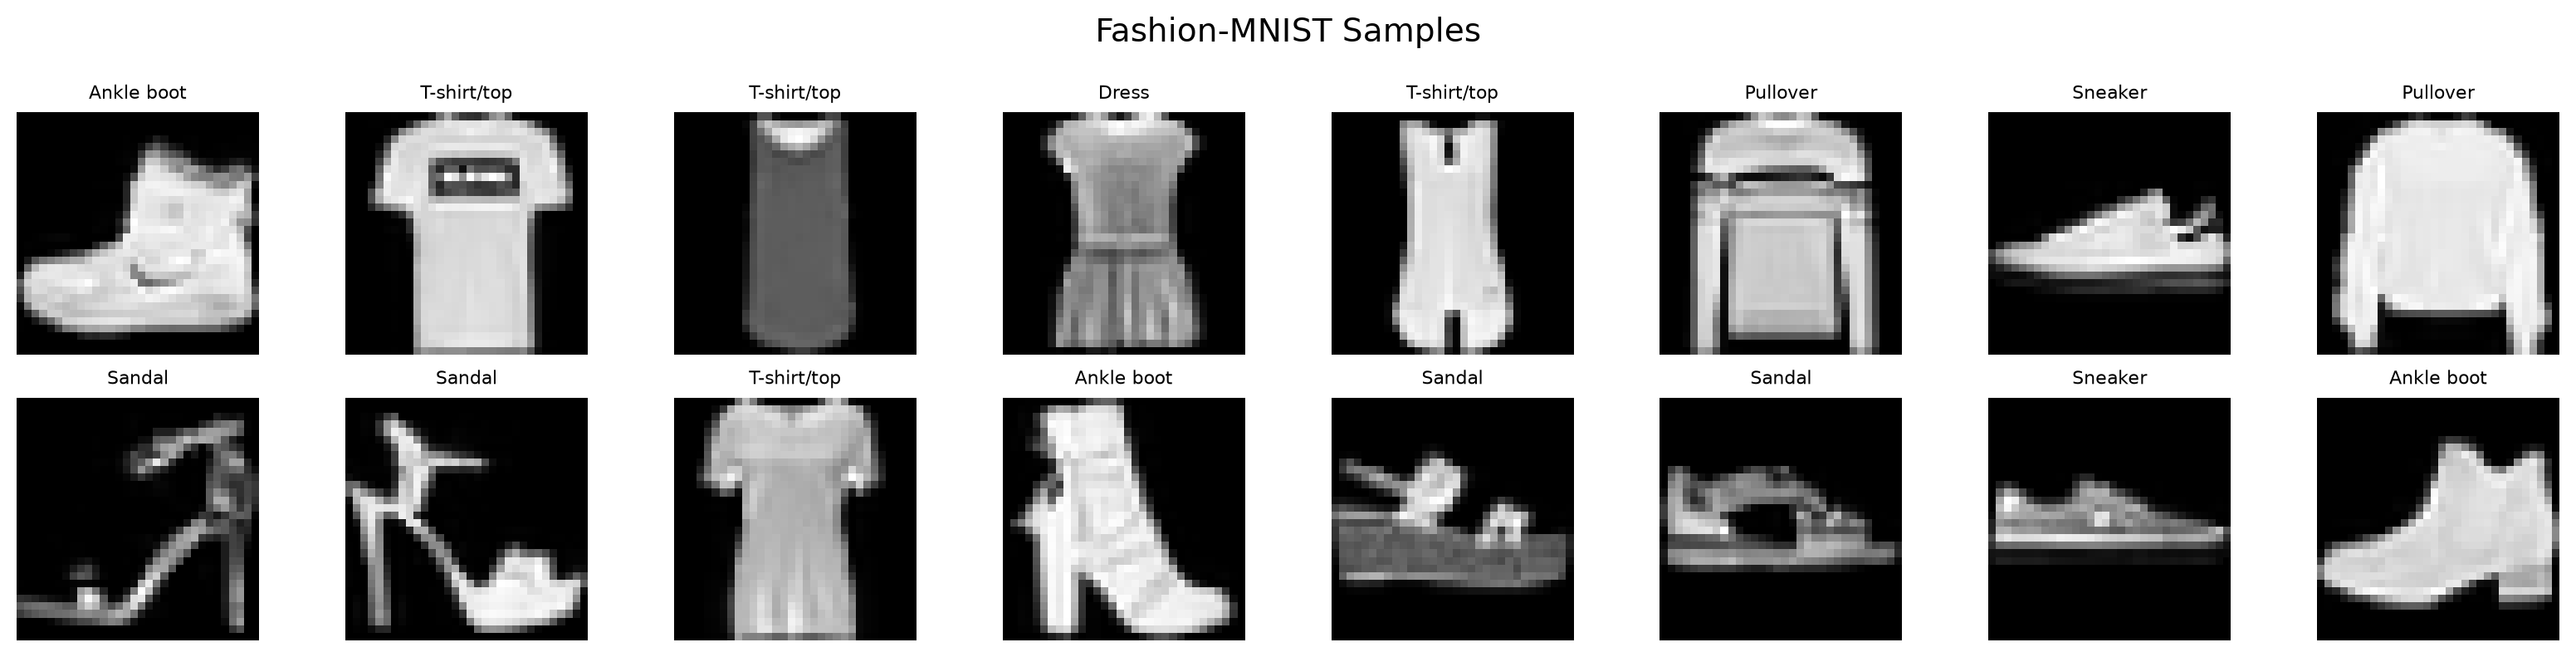

In [30]:
# visualize samples
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    img, label = full_train[i]
    ax.imshow(img.squeeze() * 0.5 + 0.5, cmap='gray')  # denormalize
    ax.set_title(class_names[label], fontsize=8)
    ax.axis('off')
plt.suptitle('Fashion-MNIST Samples', fontsize=14)
plt.tight_layout(); plt.show()


### Model Definition

In [31]:
class FashionCNN(nn.Module):
    """CNN for Fashion-MNIST classification."""
    def __init__(self, num_classes=10):
        super().__init__()
        # conv backbone
        self.features = nn.Sequential(
            # block 1: 1 → 32 channels
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                               # 32x32 → 16x16

            # block 2: 32 → 64 channels
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                               # 16x16 → 8x8

            # block 3: 64 → 128 channels
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),                               # 8x8 → 4x4
        )
        # classifier head
        self.classifier = nn.Sequential(
            nn.Flatten(),                                  # 128*4*4 = 2048
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = FashionCNN(num_classes=10).to(DEVICE)
print(model)

# parameter count
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal params: {total_params:,} | Trainable: {trainable_params:,}')


FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_featu

### Training Loop

In [32]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total


In [33]:
# training config
EPOCHS = 15
LR = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

# training history
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_acc = evaluate(model, val_loader, criterion, DEVICE)
    scheduler.step()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    print(f'Epoch {epoch+1:02d}/{EPOCHS} | '
          f'Train Loss: {train_loss:.4f}, Acc: {train_acc:.1f}% | '
          f'Val Loss: {val_loss:.4f}, Acc: {val_acc:.1f}%')


Epoch 01/15 | Train Loss: 0.5063, Acc: 81.8% | Val Loss: 0.3544, Acc: 86.4%
Epoch 02/15 | Train Loss: 0.3475, Acc: 87.4% | Val Loss: 0.2897, Acc: 89.4%
Epoch 03/15 | Train Loss: 0.3013, Acc: 89.1% | Val Loss: 0.2723, Acc: 90.2%
Epoch 04/15 | Train Loss: 0.2725, Acc: 90.1% | Val Loss: 0.2407, Acc: 91.4%
Epoch 05/15 | Train Loss: 0.2531, Acc: 91.0% | Val Loss: 0.2545, Acc: 90.9%
Epoch 06/15 | Train Loss: 0.2074, Acc: 92.5% | Val Loss: 0.2232, Acc: 91.9%
Epoch 07/15 | Train Loss: 0.1935, Acc: 93.0% | Val Loss: 0.2014, Acc: 92.6%
Epoch 08/15 | Train Loss: 0.1831, Acc: 93.4% | Val Loss: 0.2043, Acc: 92.8%
Epoch 09/15 | Train Loss: 0.1734, Acc: 93.7% | Val Loss: 0.1997, Acc: 92.6%
Epoch 10/15 | Train Loss: 0.1661, Acc: 93.9% | Val Loss: 0.2007, Acc: 92.5%
Epoch 11/15 | Train Loss: 0.1412, Acc: 94.7% | Val Loss: 0.1975, Acc: 93.0%
Epoch 12/15 | Train Loss: 0.1322, Acc: 95.2% | Val Loss: 0.1829, Acc: 93.6%
Epoch 13/15 | Train Loss: 0.1254, Acc: 95.5% | Val Loss: 0.1873, Acc: 93.3%
Epoch 14/15 

### Training Curves

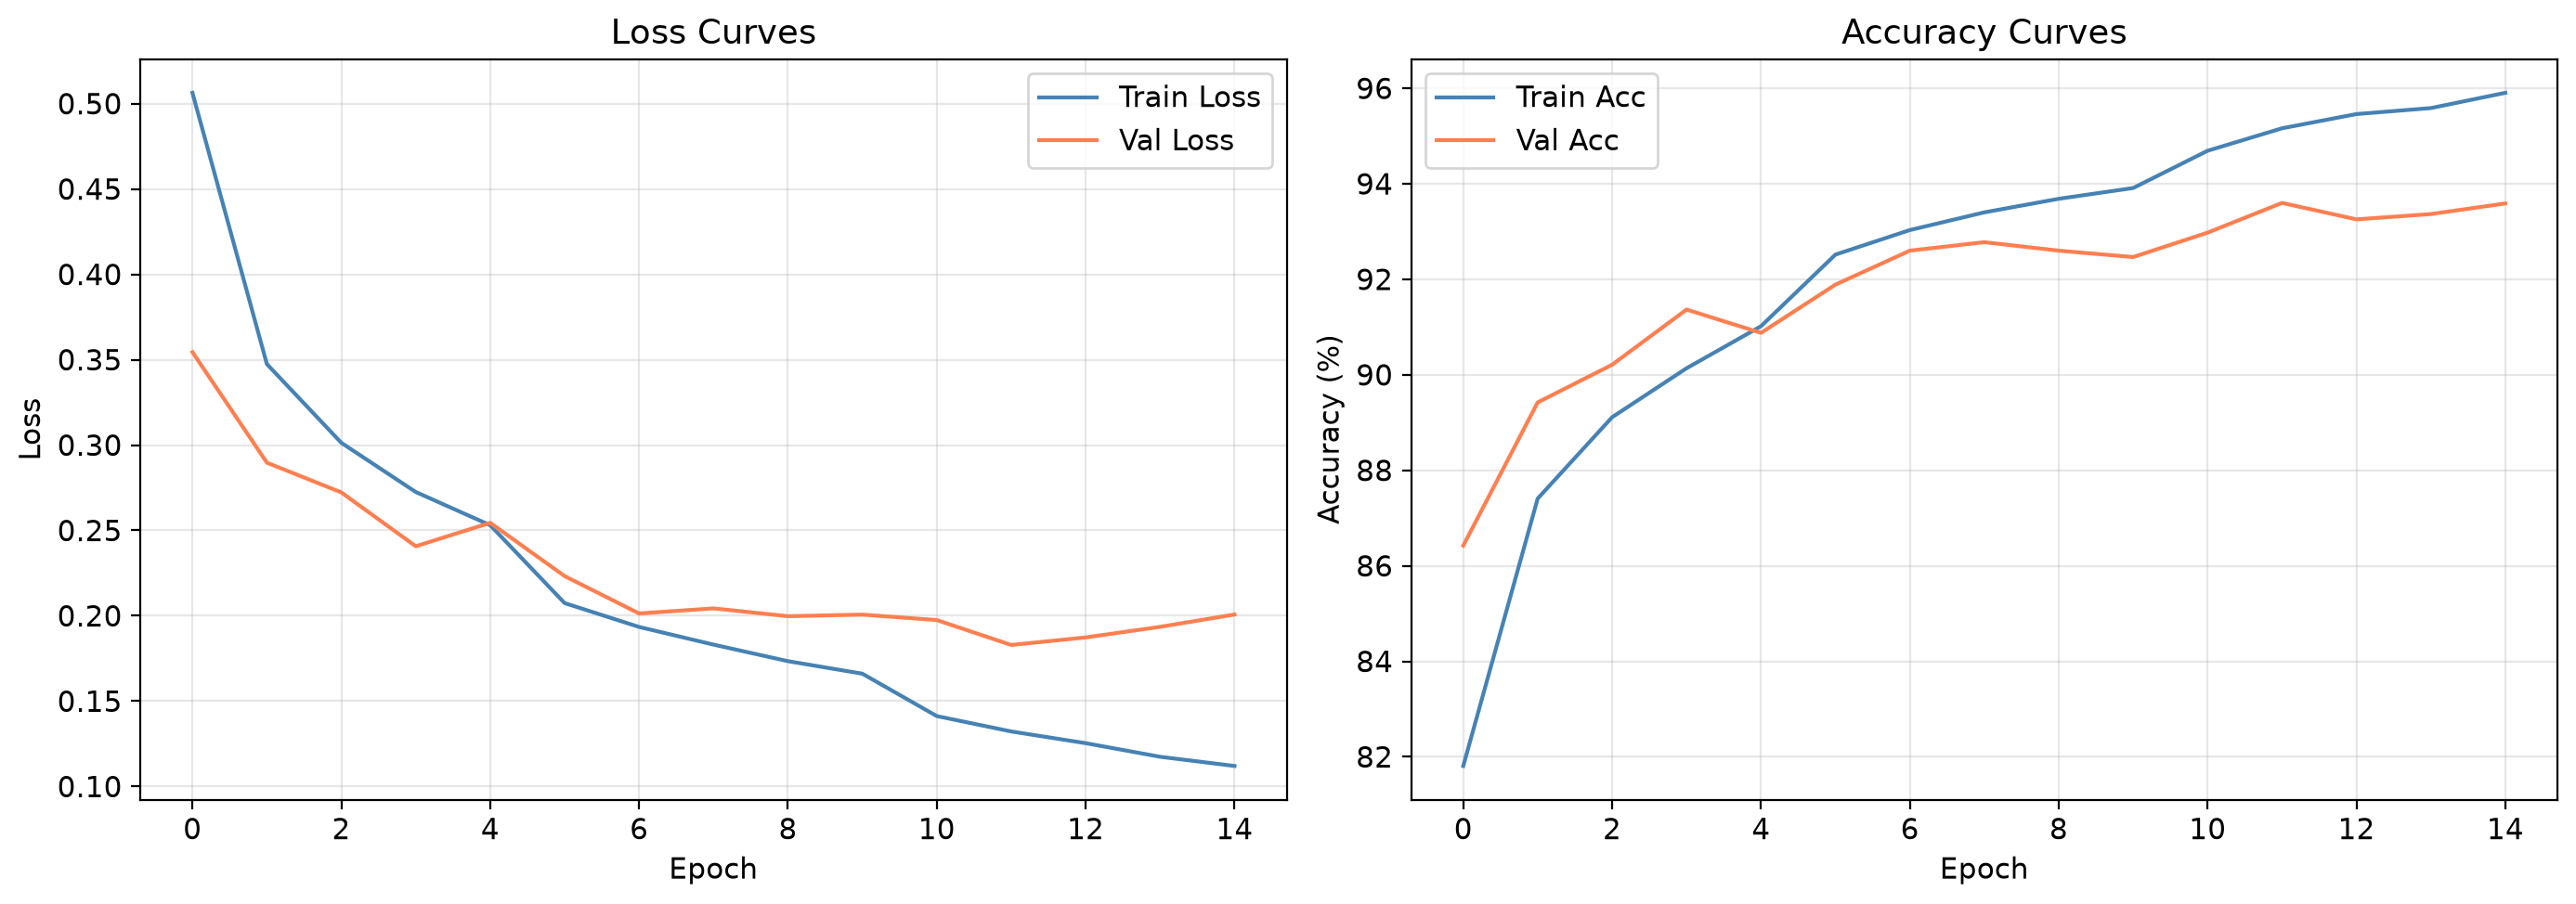

In [34]:
# plot loss and accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['train_loss'], label='Train Loss', color='steelblue')
ax1.plot(history['val_loss'], label='Val Loss', color='coral')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Loss Curves'); ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(history['train_acc'], label='Train Acc', color='steelblue')
ax2.plot(history['val_acc'], label='Val Acc', color='coral')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Accuracy Curves'); ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()


### Test Evaluation

In [35]:
# final test evaluation
test_loss, test_acc = evaluate(model, test_loader, criterion, DEVICE)
print(f'Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}%')


Test Loss: 0.2151 | Test Accuracy: 93.37%


### Visualize Predictions

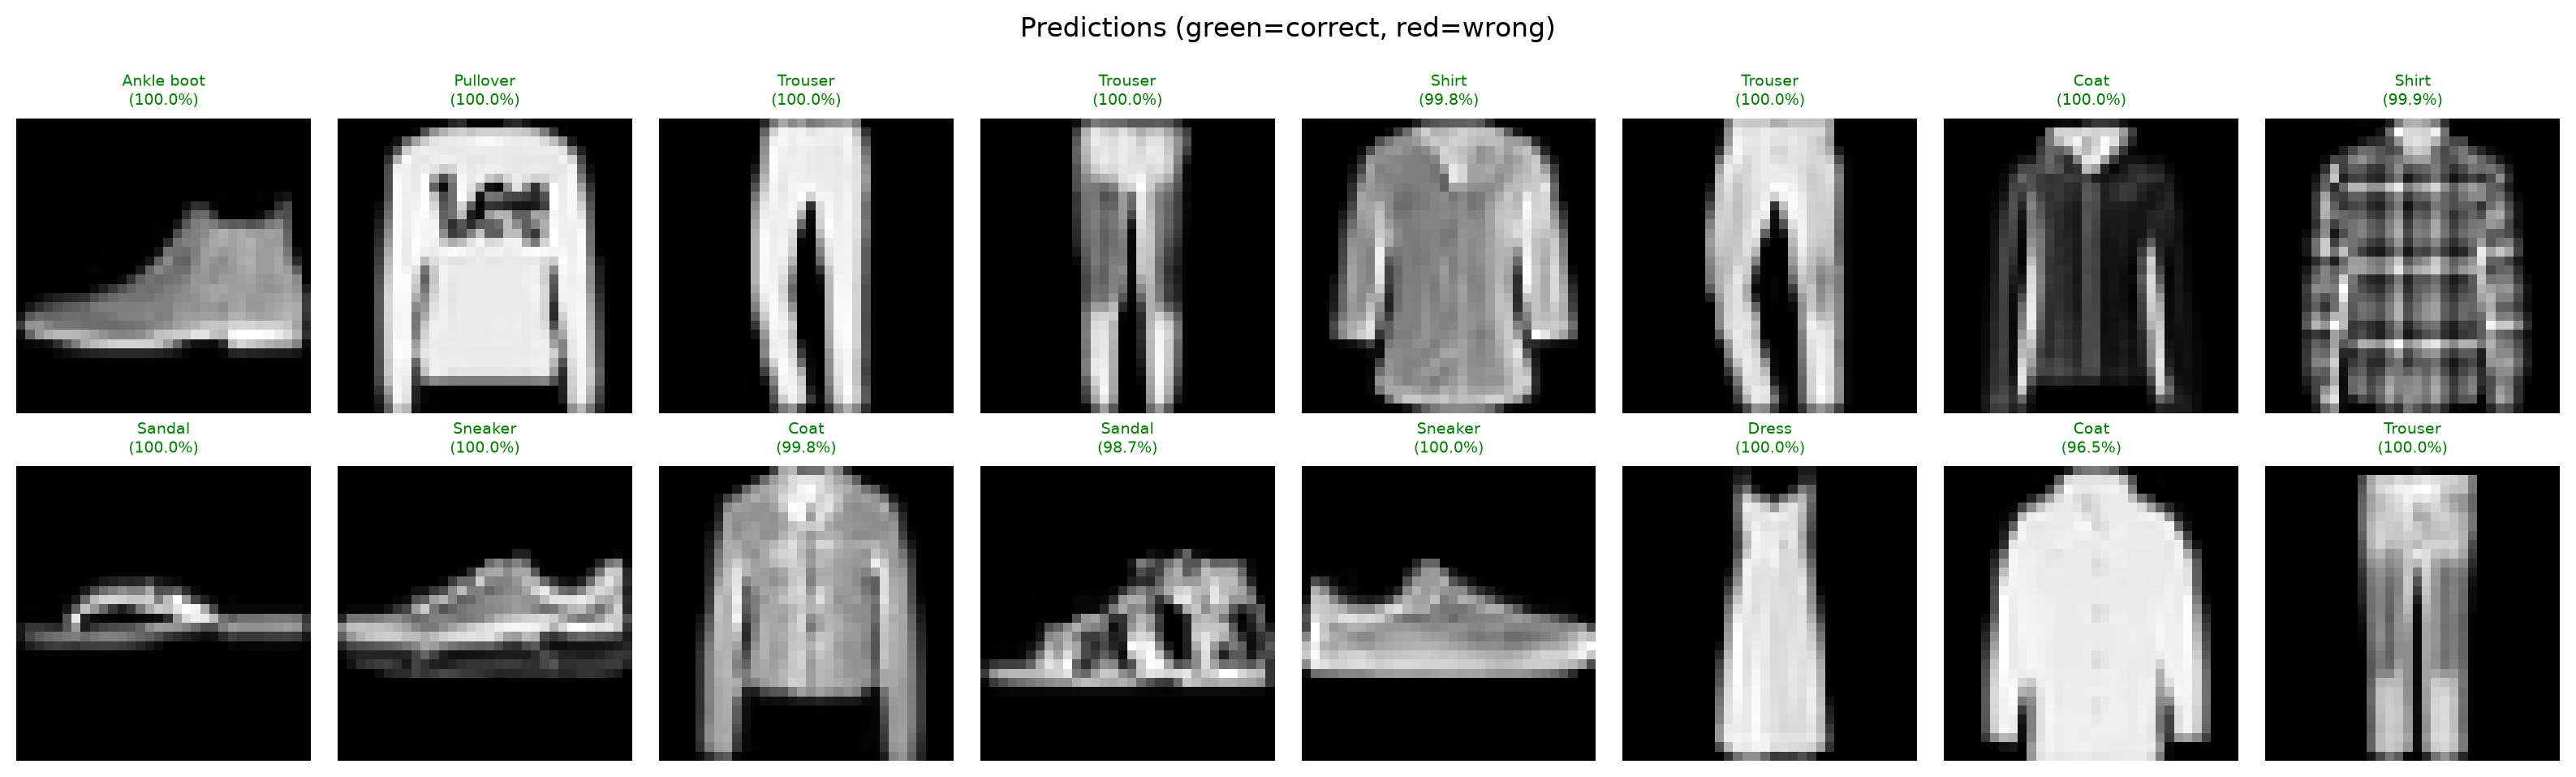

In [36]:
# sample predictions
model.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(DEVICE), labels.to(DEVICE)
with torch.no_grad():
    outputs = model(images)
    probs = F.softmax(outputs, dim=1)
    _, preds = outputs.max(1)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for i, ax in enumerate(axes.flat):
    img = images[i].cpu().squeeze() * 0.5 + 0.5
    ax.imshow(img, cmap='gray')
    color = 'green' if preds[i] == labels[i] else 'red'
    ax.set_title(f'{class_names[preds[i]]}\n({probs[i, preds[i]]:.1%})',
                 fontsize=7, color=color)
    ax.axis('off')
plt.suptitle('Predictions (green=correct, red=wrong)', fontsize=12)
plt.tight_layout(); plt.show()


### Visualize Learned Filters (Layer 1)

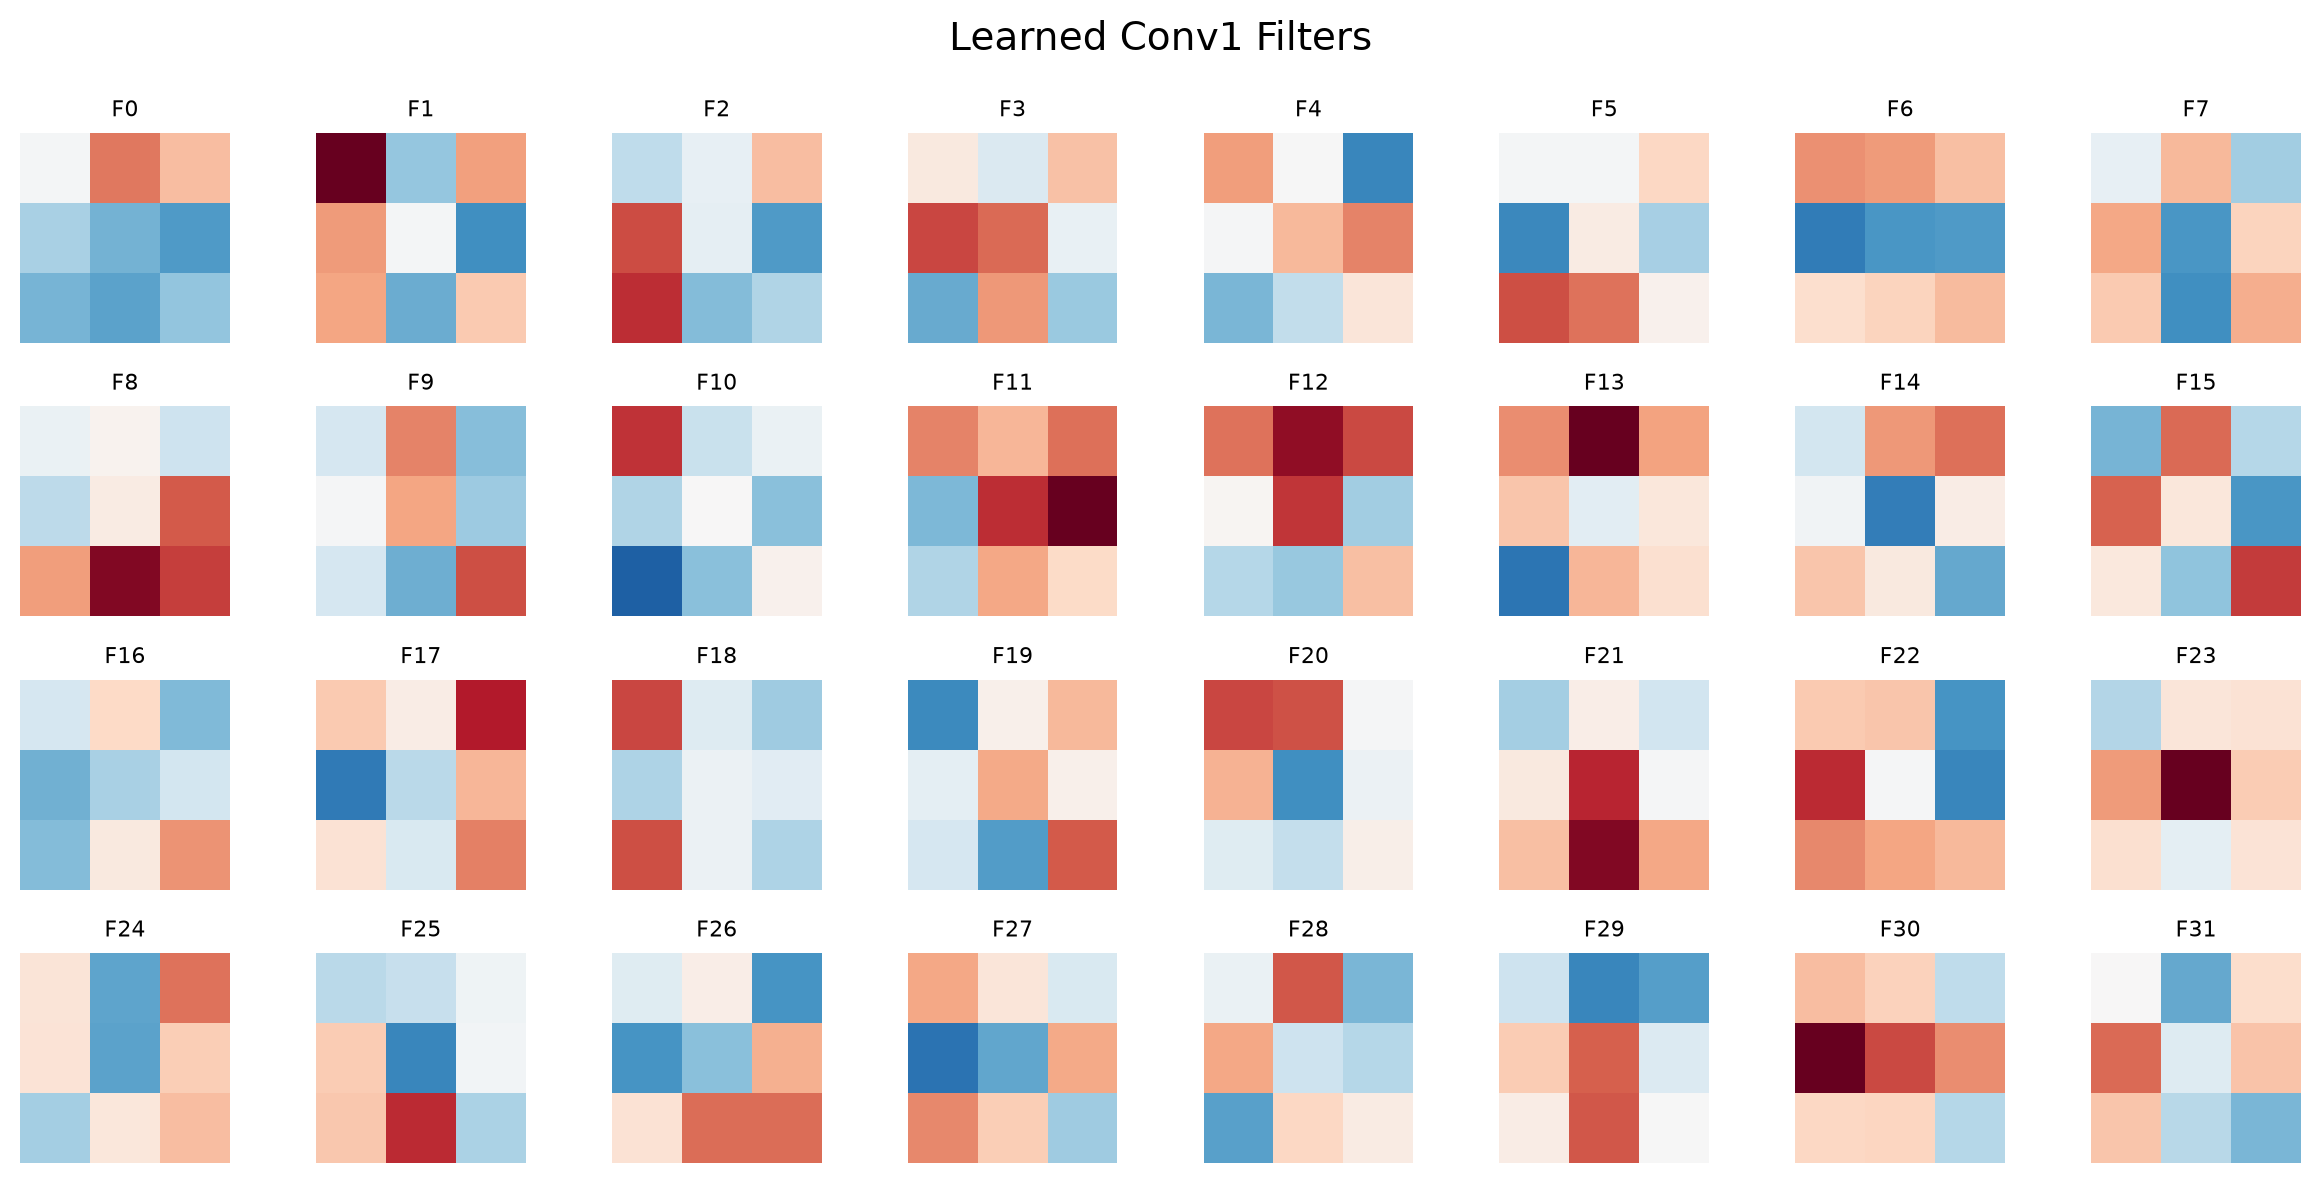

In [37]:
# visualize first conv layer filters
filters = model.features[0].weight.data.cpu()
n_filters = filters.shape[0]
n_cols = 8
n_rows = (n_filters + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 1.5))
for i, ax in enumerate(axes.flat):
    if i < n_filters:
        ax.imshow(filters[i, 0], cmap='RdBu', vmin=-0.5, vmax=0.5)
        ax.set_title(f'F{i}', fontsize=8)
    ax.axis('off')
plt.suptitle('Learned Conv1 Filters', fontsize=14)
plt.tight_layout(); plt.show()


---
# Multi-Head CNN Extension

Adding a secondary regression head to predict average pixel intensity alongside classification.


In [38]:
class MultiTaskFashionCNN(nn.Module):
    """Multi-head CNN: classification + brightness regression."""
    def __init__(self, num_classes=10):
        super().__init__()
        # shared backbone
        self.backbone = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        )
        # classification head
        self.cls_head = nn.Sequential(
            nn.Flatten(), nn.Linear(128*4*4, 256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )
        # regression head (predict avg brightness)
        self.reg_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(128, 32), nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        feat = self.backbone(x)
        cls_out = self.cls_head(feat)
        reg_out = self.reg_head(feat)
        return cls_out, reg_out

mt_model = MultiTaskFashionCNN(10).to(DEVICE)
print(mt_model)


MultiTaskFashionCNN(
  (backbone): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (cls_head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, b

In [52]:
# multi-task training
mt_criterion_cls = nn.CrossEntropyLoss()
mt_criterion_reg = nn.SmoothL1Loss()
mt_optimizer = torch.optim.Adam(mt_model.parameters(), lr=1e-3)

LAMBDA_CLS, LAMBDA_REG = 1.0, 0.5
MT_EPOCHS = 8

history = {'loss': [], 'acc': []}

for epoch in range(MT_EPOCHS):
    mt_model.train()
    epoch_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        # target for regression: average brightness of each image
        brightness = images.mean(dim=[1, 2, 3], keepdim=False).unsqueeze(1)

        mt_optimizer.zero_grad()
        cls_out, reg_out = mt_model(images)

        loss_cls = mt_criterion_cls(cls_out, labels)
        loss_reg = mt_criterion_reg(reg_out, brightness)
        loss = LAMBDA_CLS * loss_cls + LAMBDA_REG * loss_reg

        loss.backward()
        mt_optimizer.step()

        epoch_loss += loss.item() * images.size(0)
        _, preds = cls_out.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

        history['loss'].append(epoch_loss/total)

    train_acc = 100.0 * correct / total
    history['acc'].append(train_acc)

    print(f'Epoch {epoch+1:02d}/{MT_EPOCHS} | '
          f'Loss: {epoch_loss/total:.4f} | Acc: {train_acc:.1f}%')


Epoch 01/8 | Loss: 0.0600 | Acc: 98.0%
Epoch 02/8 | Loss: 0.0528 | Acc: 98.0%
Epoch 03/8 | Loss: 0.0565 | Acc: 97.9%
Epoch 04/8 | Loss: 0.0537 | Acc: 98.0%
Epoch 05/8 | Loss: 0.0528 | Acc: 98.0%
Epoch 06/8 | Loss: 0.0536 | Acc: 98.1%
Epoch 07/8 | Loss: 0.0512 | Acc: 98.1%
Epoch 08/8 | Loss: 0.0477 | Acc: 98.3%


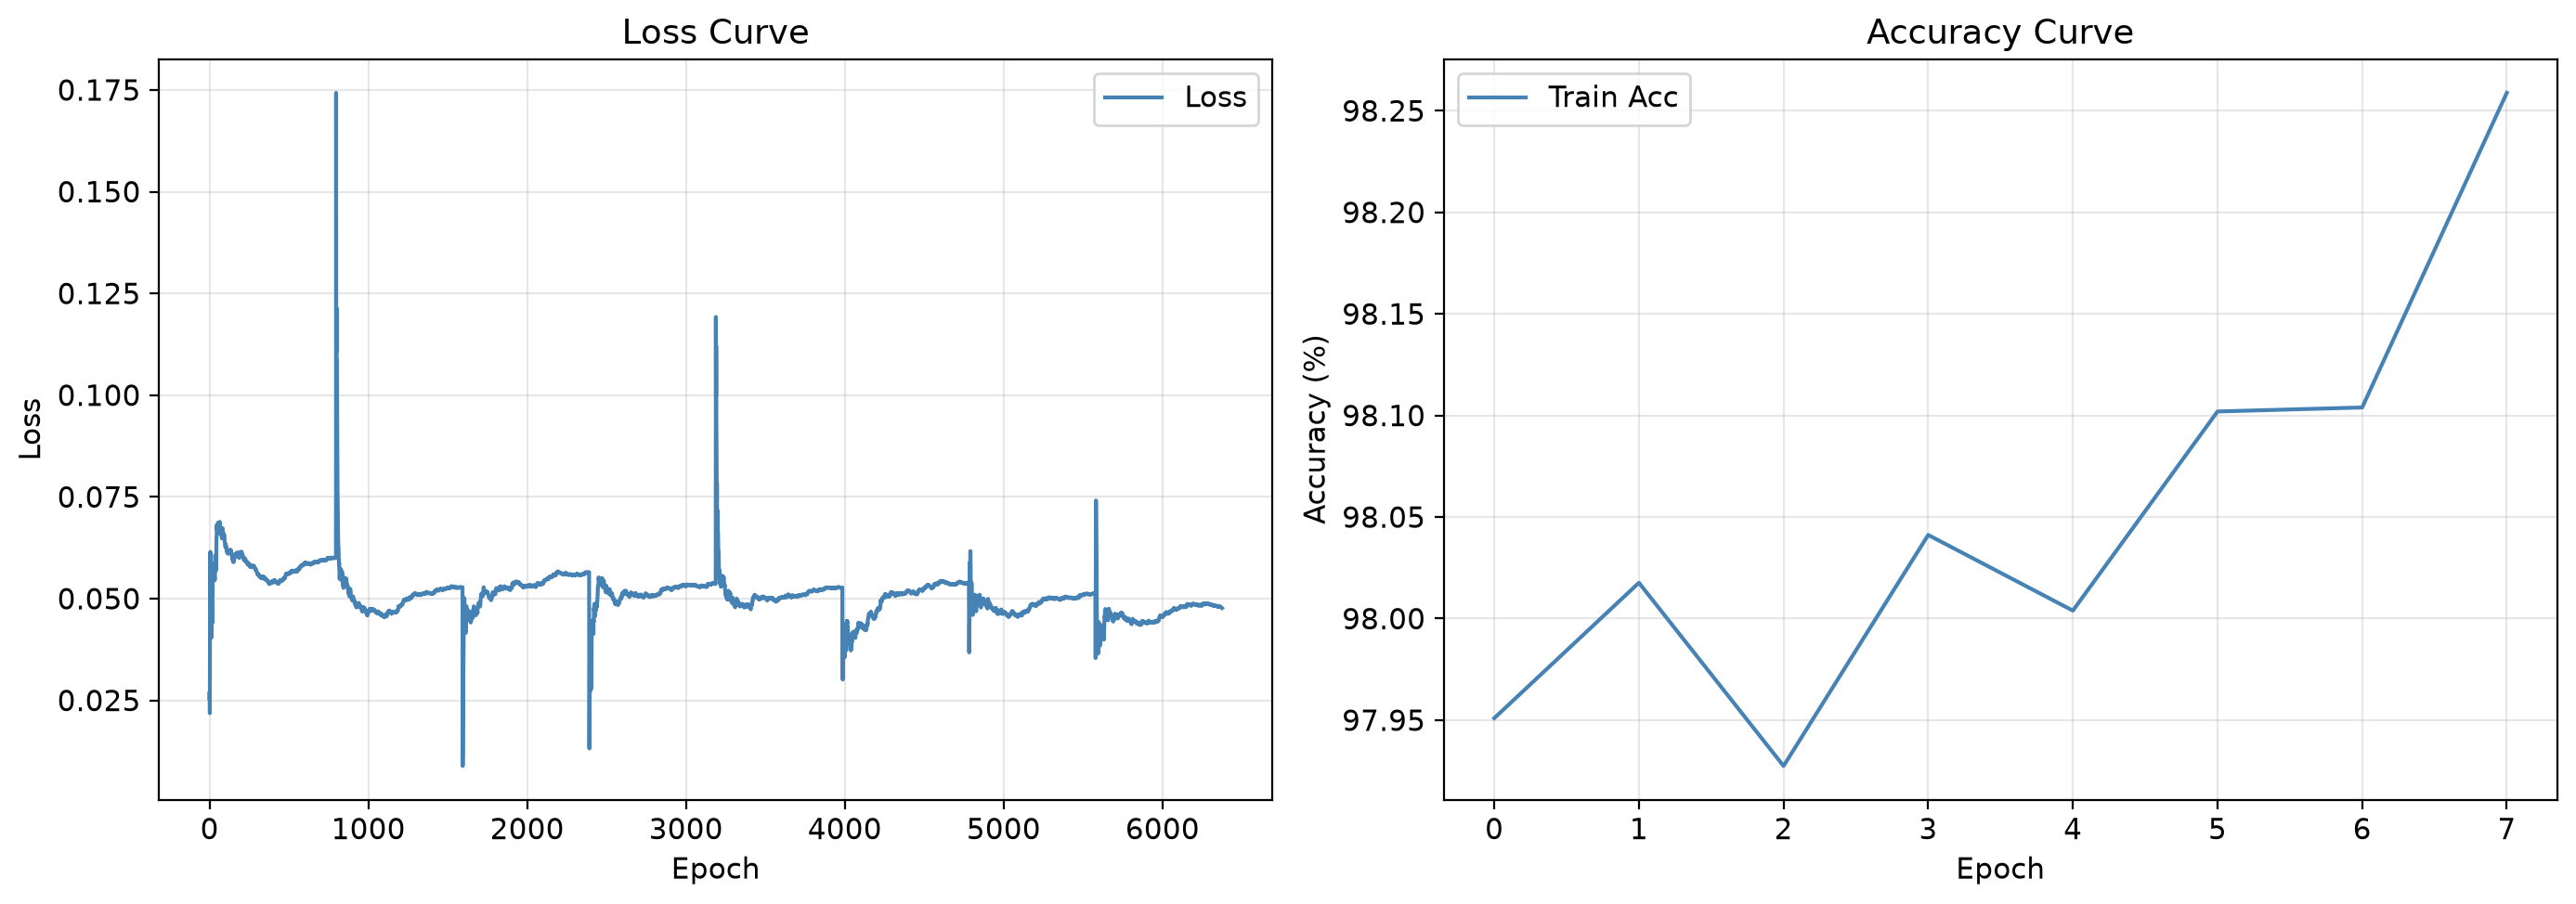

In [53]:
# plot loss and accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history['loss'], label='Loss', color='steelblue')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Loss Curve'); ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(history['acc'], label='Train Acc', color='steelblue')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Accuracy Curve'); ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

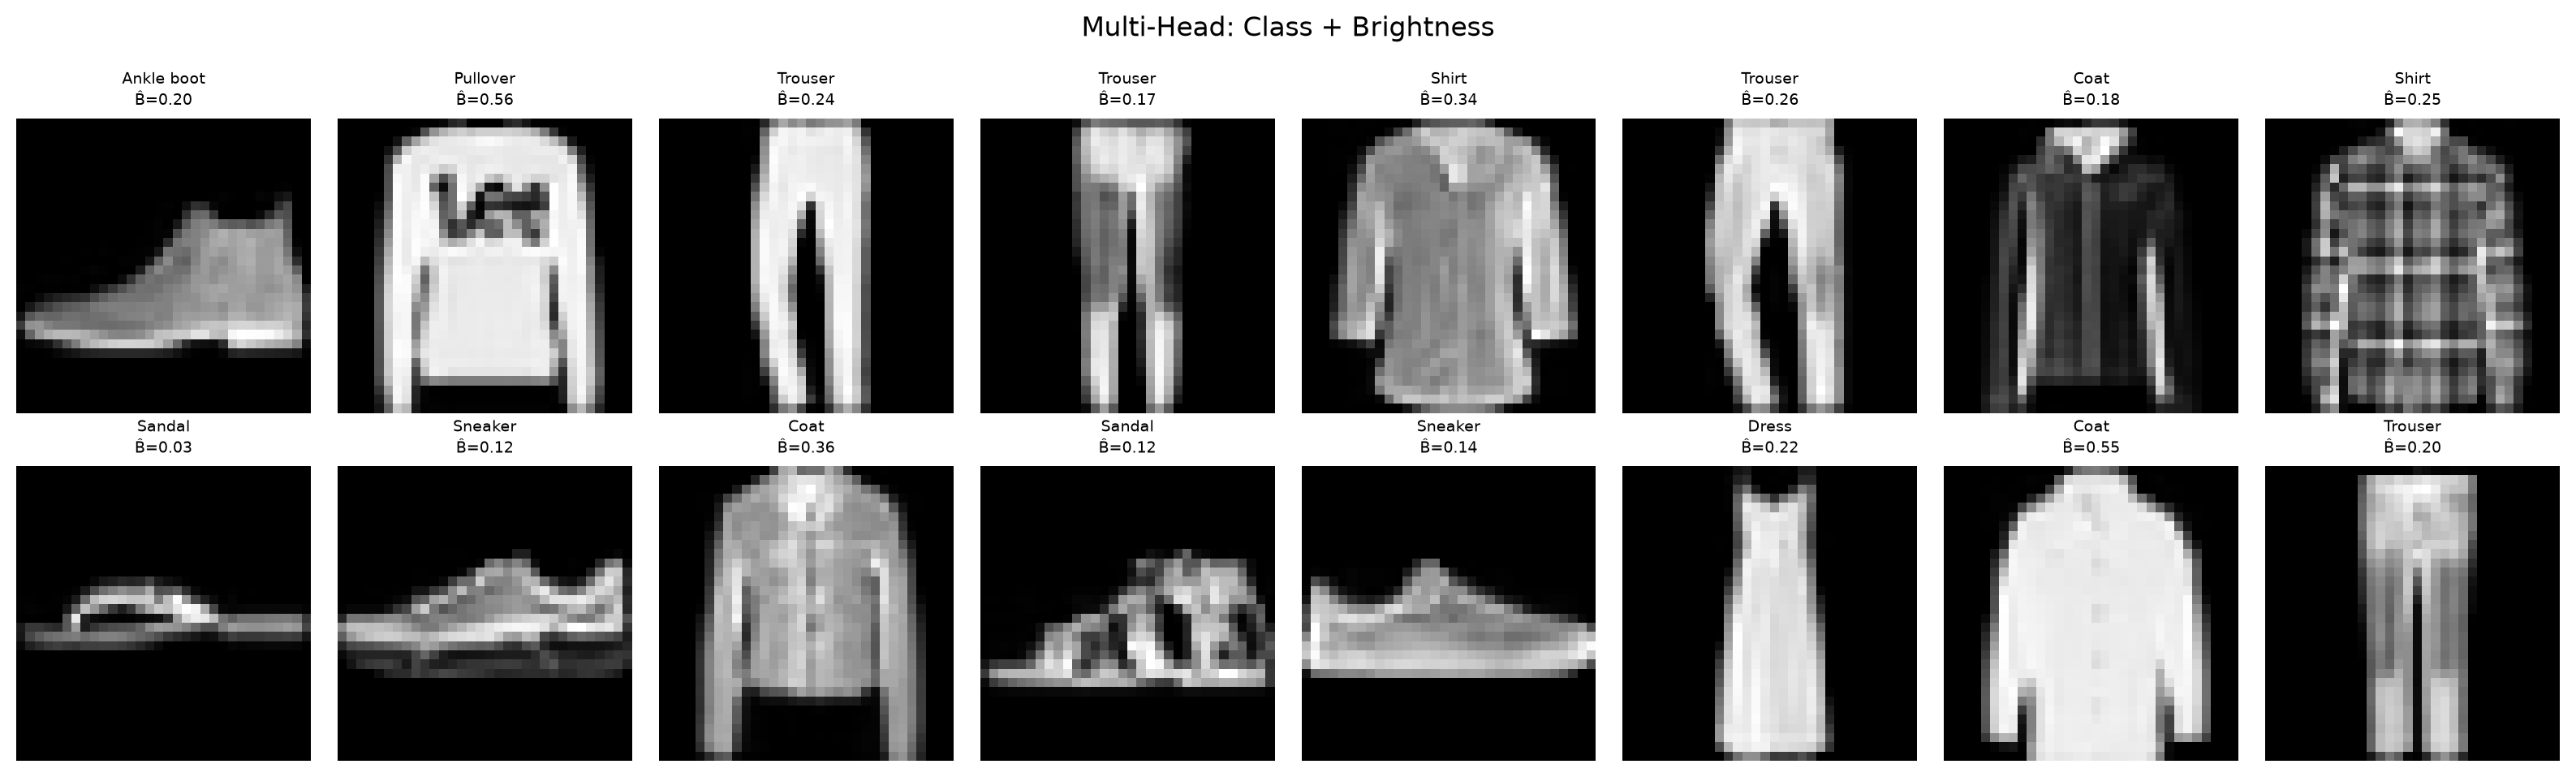

In [54]:
# multi-head inference demo
mt_model.eval()
images, labels = next(iter(test_loader))
images = images.to(DEVICE)

with torch.no_grad():
    cls_out, reg_out = mt_model(images)
    _, preds = cls_out.max(1)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for i, ax in enumerate(axes.flat):
    img = images[i].cpu().squeeze() * 0.5 + 0.5
    actual_brightness = img.mean().item()
    pred_brightness = reg_out[i].item() * 0.5 + 0.5  # denormalize
    ax.imshow(img, cmap='gray')
    ax.set_title(f'{class_names[preds[i]]}\nB̂={pred_brightness:.2f}', fontsize=7)
    ax.axis('off')
plt.suptitle('Multi-Head: Class + Brightness', fontsize=12)
plt.tight_layout(); plt.show()


---
### Key Takeaways

1. **CNNs** exploit spatial structure through weight-sharing (convolution) and local receptive fields
2. **Conv → BN → ReLU → Pool** is the standard building block
3. **Feature hierarchy**: edges → textures → objects as depth increases
4. **Flatten / GAP** transitions from spatial features to dense classification
5. **Multi-head architectures** share a backbone and split into task-specific branches
6. **Combined losses** $\mathcal{L}_{total} = \sum \lambda_i \mathcal{L}_i$ with backprop through shared weights
